<h2 style="font-weight:600;color:#4f7a9b">Selecting the number of clusters with Silhouette Analysis</h2>

Silhouette analysis studies the separation **distance between the resulting clusters**.<br/>
It takes values in the range [-1, +1] as follows:

| COEFFICIENT | EXPLANATION |
| --- | --- |
| +1 | The sample is far away from the neighboring clusters. |
| 0 | The sample is on/very close to the boundary between two clusters. |
| -1 | The sample has been assigned to the wrong cluster |

So, we can use Silhouette Analysis to determine on the **optimal number of clusters**.

For n_clusters = 2 the average shilhouette score is : 0.70
For n_clusters = 3 the average shilhouette score is : 0.59
For n_clusters = 4 the average shilhouette score is : 0.65
For n_clusters = 5 the average shilhouette score is : 0.56
For n_clusters = 6 the average shilhouette score is : 0.49


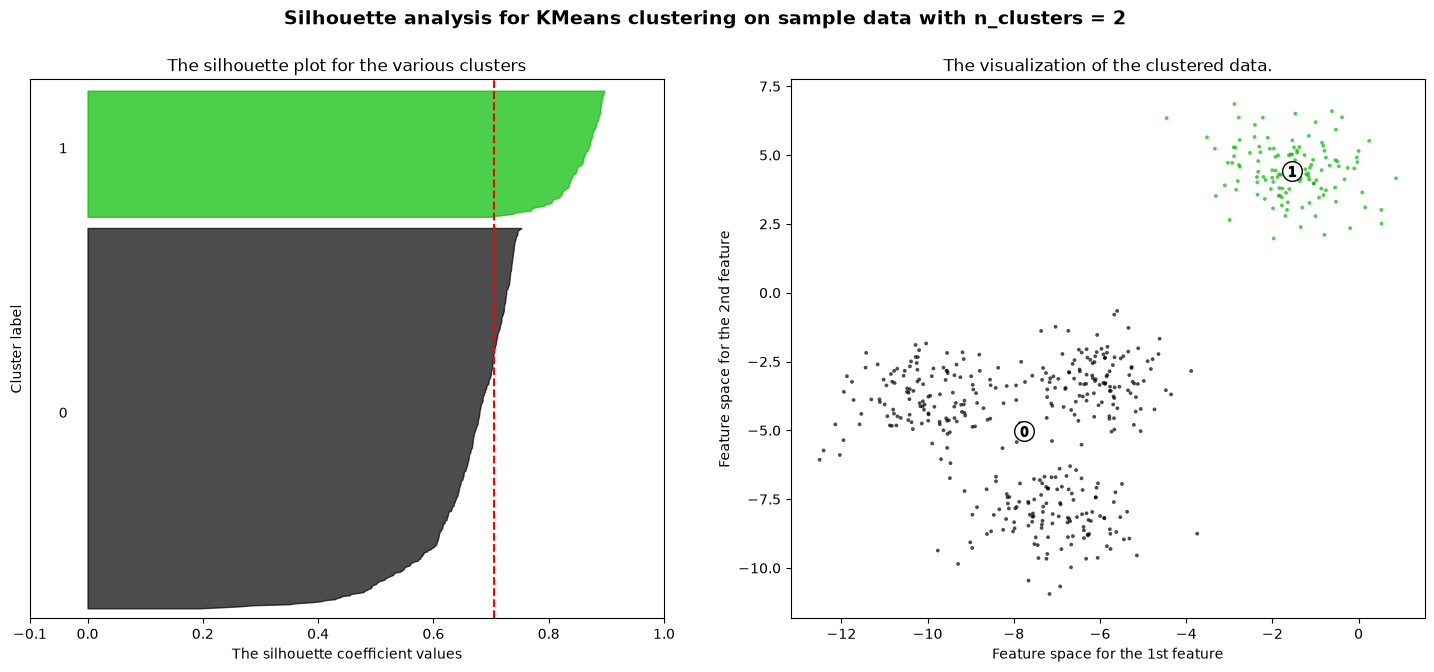

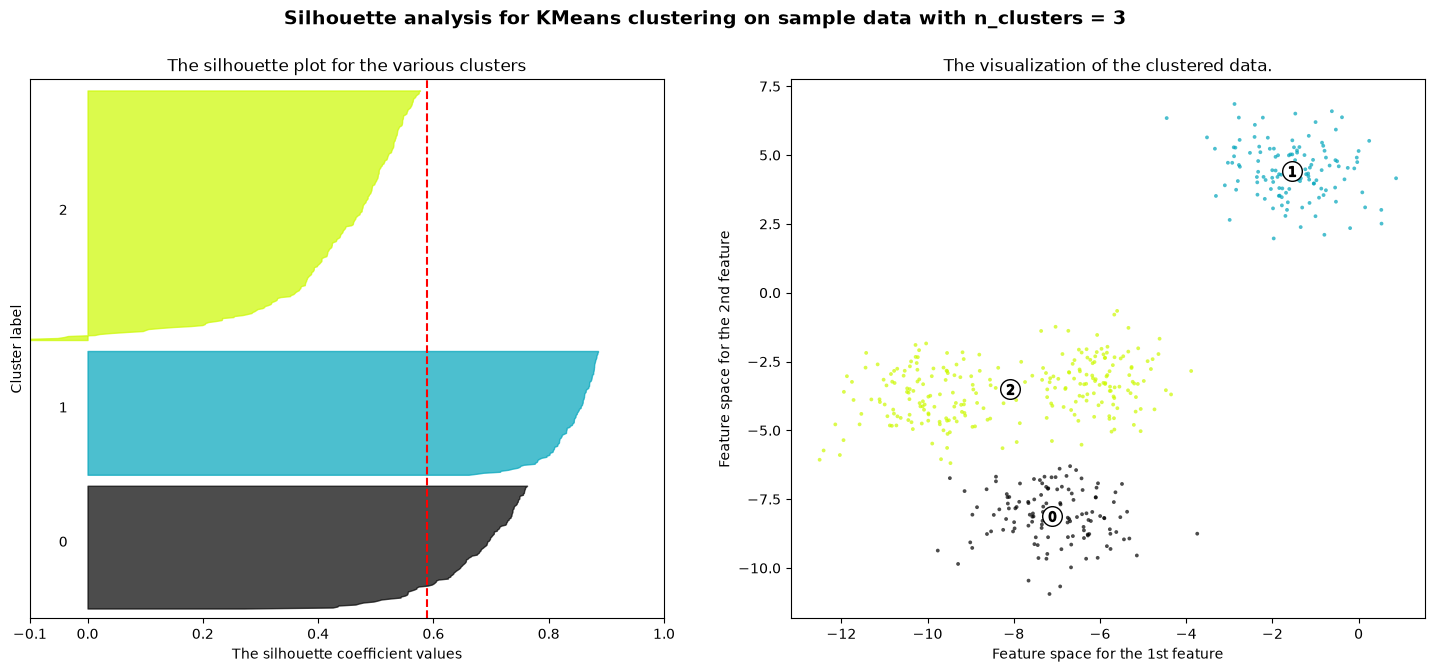

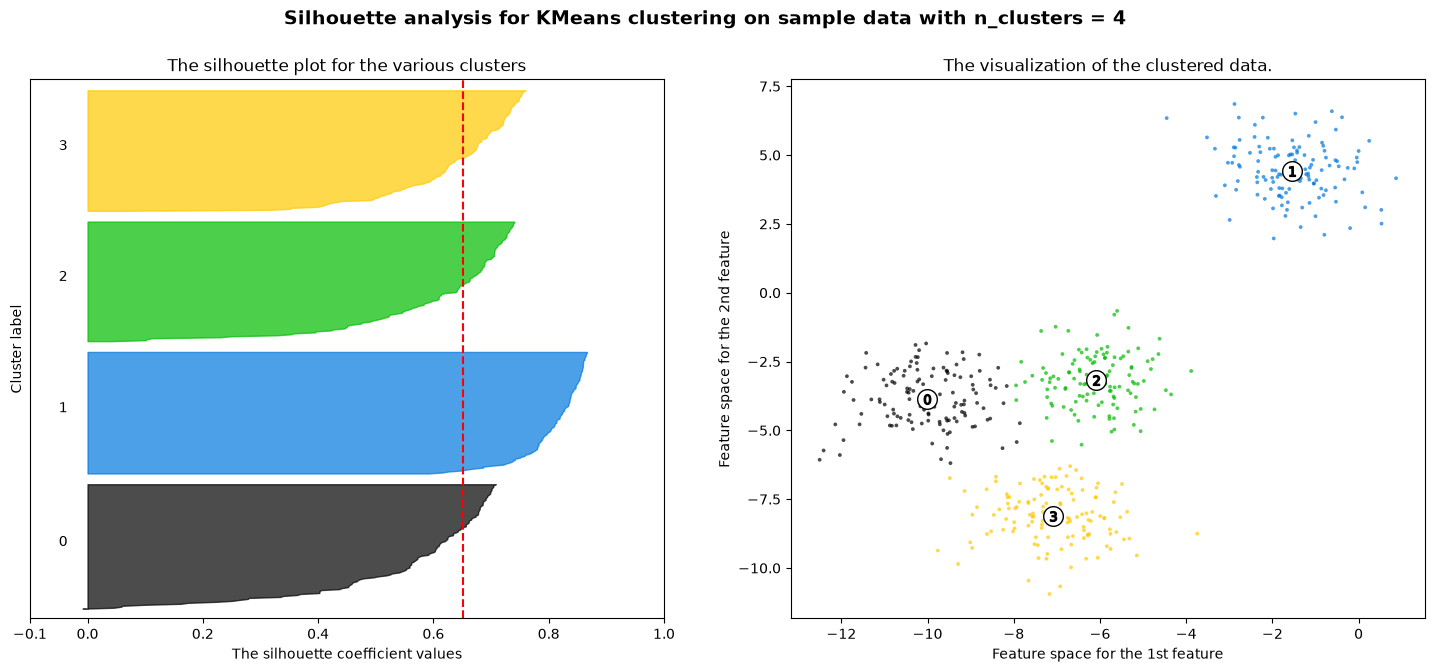

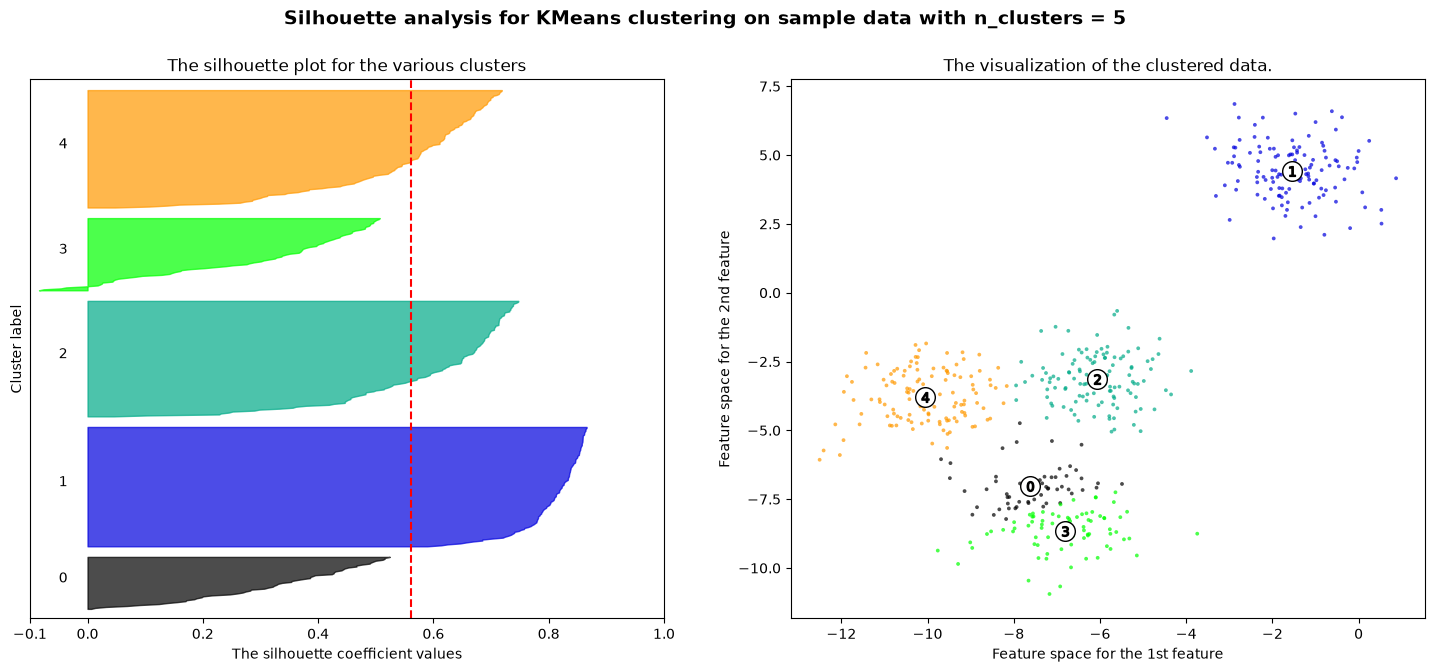

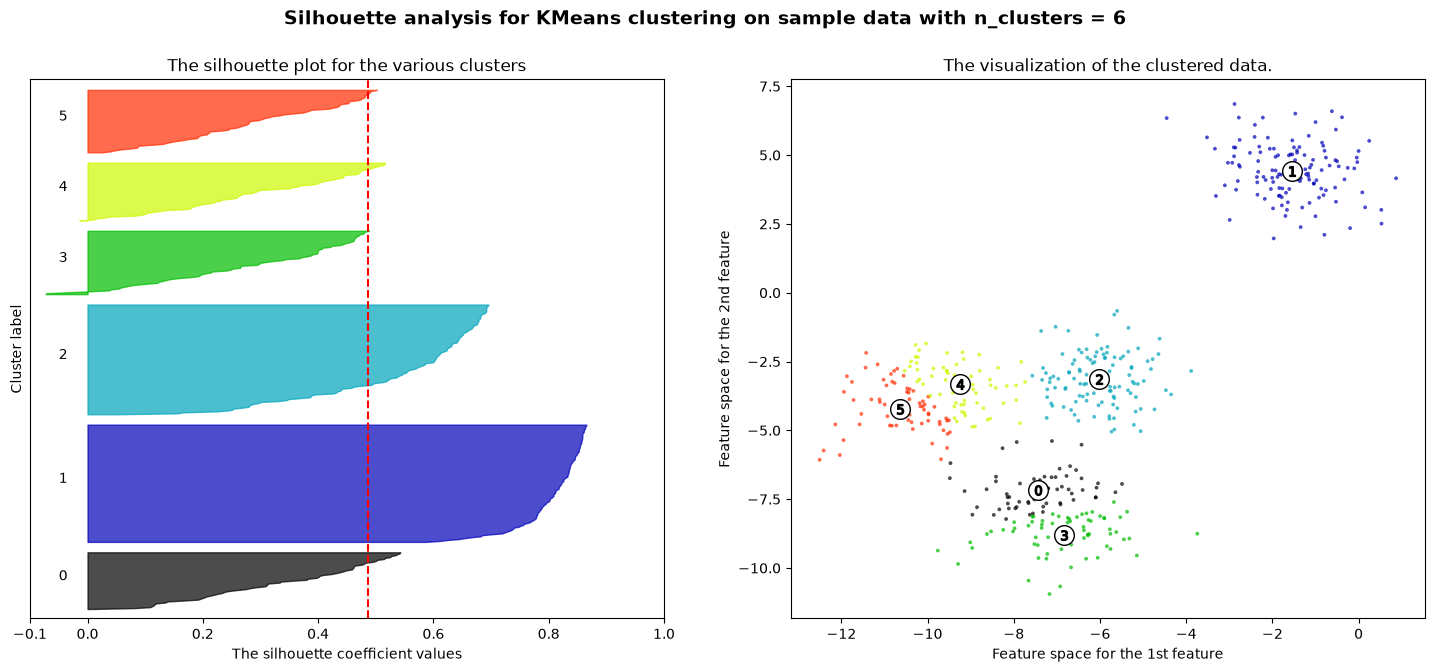

In [ ]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_samples, silhouette_score

# Generating the sample data from make_blobs.
# This particular setting has one distinct cluster and 3 clusters placed close together.
# X is the generated samples. Here each sample point is of the form
# [ -6.92324165, -10.66953197] i.e. two features.
# y is the the integer labels for cluster membership of each sample.
X, y = make_blobs(
    n_samples=500,
    n_features=2,
    centers=4,
    cluster_std=1,
    center_box=(-10.0, 10.0),
    shuffle=True,
    random_state=1,  # For reproducibility
)

range_n_clusters = [2, 3, 4, 5, 6]

# Perform Silhouette analysis for five different number of clusters:
for n_clusters in range_n_clusters:
    # Create a subplot with 1 row and 2 columns
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    # The 1st subplot is the silhouette plot.
    # The silhouette coefficient can range from -1 to 1,
    # but in this example all lie within [-0.1, 1].
    ax1.set_xlim([-0.1, 1])
    # The (n_clusters + 1)*10 is for inserting blank space between silhouette
    # plots of individual clusters, to demarcate them clearly.
    ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

    # Initialize the clusterer with n_clusters value and a random
    # generator seed of 10 for reproducibility.
    clusterer = KMeans(n_clusters=n_clusters, random_state=10)
    # Return the label cluster index, that each sample belongs to
    cluster_labels = clusterer.fit_predict(X)

    # The silhouette_score gives the average value for all the samples.
    # This gives a perspective into the density and separation of the formed clusters.
    silhouette_avg = silhouette_score(X, cluster_labels)
    print(f"For n_clusters = {n_clusters} the average shilhouette score is : {silhouette_avg:.2f}")

    # The silhouette_samples computes the silhouette scores for each sample separately.
    sample_silhouette_values = silhouette_samples(X, cluster_labels)
    y_lower = 10

    # For every cluster created out of n_clusters:
    for i in range(n_clusters):
        # Aggregate the silhouette scores for samples belonging to
        # cluster i, and sort them.
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        ith_cluster_silhouette_values.sort()
        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Label the silhouette plots with their cluster numbers at the middle.
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
        # Compute the new y_lower for next plot.
        y_lower = y_upper + 10

    ax1.set_title("The silhouette plot for the various clusters")
    ax1.set_xlabel("The silhouette coefficient values")
    ax1.set_ylabel("Cluster label")
    # The vertical line for average silhouette score of all the values.
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")
    # Clear the y axis labels/ticks
    ax1.set_yticks([])
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    # 2nd plot showing the actual clusters formed
    colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(X[:, 0], X[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k")

    # Label the clusters
    centers = clusterer.cluster_centers_
    # Draw white circles at cluster centers.
    ax2.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="o",
        c="white",
        alpha=1,
        s=200,
        edgecolor="k",
    )

    for i, c in enumerate(centers):
        ax2.scatter(c[0], c[1], marker="$%d$" % i, alpha=1, s=50, edgecolor="k")

    ax2.set_title("The visualization of the clustered data.")
    ax2.set_xlabel("Feature space for the 1st feature")
    ax2.set_ylabel("Feature space for the 2nd feature")

    plt.suptitle(
        f"Silhouette analysis for KMeans clustering on sample data with n_clusters = {n_clusters}",
        fontsize=14,
        fontweight="bold",
    )

plt.show()

The above Silhouette analysis shows that, n_clusters 3, 5 and 6, produce below average results. On the other hand, 2 and 4 are more close to the desired value of 1.

For n_clusters equal to 2, note that one of the plots is much thicker than the other one. Using 4 clusters however, produces 4 clusters of similar size.